In [1]:
%matplotlib inline

# 导入必要的库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置 Seaborn 默认样式（darkgrid 与参考图一致）
sns.set()

In [2]:
# 读取数据
data = pd.read_csv("YouTube.csv")

In [3]:
# 清理频道名称中的多余空格（例如 'Ed Sheeran ' 变为 'Ed Sheeran'）
data['Channel'] = data['Channel'].str.strip()

# 按订阅数降序排序，确保两张图的频道顺序一致
data = data.sort_values(by='Subs (in millions)', ascending=False).reset_index(drop=True)

# 将宽格式转换为长格式
# id_vars='Channel' 保持不变，value_vars 为数值列
df = data.melt(id_vars='Channel',
               value_vars=['Subs (in millions)', 'Views (in millions)'],
               var_name='Type', value_name='Count')

# 修改 Type 列的显示值，使其与参考图一致
df['Type'] = df['Type'].replace({
    'Subs (in millions)': 'Subscribers',
    'Views (in millions)': 'Views'
})

D:\Anaconda\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


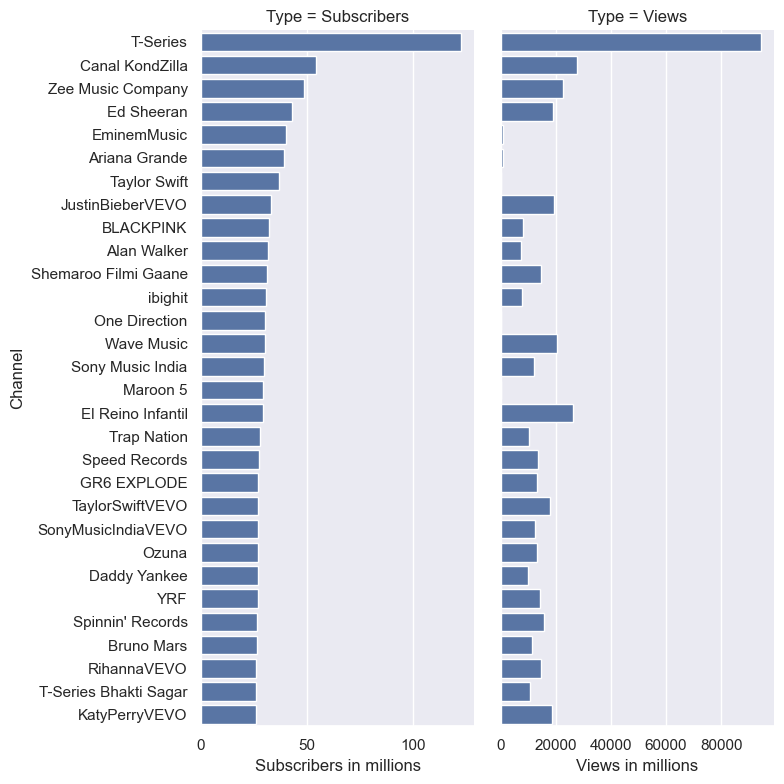

In [4]:
# 创建 FacetGrid，按 Type 分成两列
g = sns.FacetGrid(df, col='Type', sharey=True, sharex=False, height=8, aspect=0.5)

# 绘制水平条形图
g.map(sns.barplot, 'Count', 'Channel')

# 调整每个子图的 X 轴标签
axes = g.axes.flatten()
axes[0].set_xlabel('Subscribers in millions')
axes[1].set_xlabel('Views in millions')

# 调整整体布局
plt.tight_layout()

# 显示图形
plt.show()